# Real-time carbon accounting and material transition for hydrogen systems

**Compact gurobipy formulation of the Texas TVEF battery case study.**

The whole model lives in [`tvef_model.py`](tvef_model.py) (same folder): data loading, resource/process
declarations, the uncertainty-handle table `PARAMS`, `make_inputs`, the `H2System` model class and the Excel
post-processing. This notebook only runs experiments. The formulation is the same case study as
`Texas TVEF Battery.ipynb` (energiapy) and `Texas TVEF Battery Pyomo.ipynb`, but written directly with the gurobipy
matrix API: one `addMVar` per variable family and one vectorized constraint per equation. It reproduces the
validated objectives (cost 257,643,901.59 USD, GWP-min 2,228,411.58 kg CO2e) to 1e-8 and solves in ~10 s.

Output files are prefixed `Gurobipy_` and the sweep pickles go to `res_red_gurobipy/`, so nothing from the other
notebooks is overwritten.

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

## Model summary

Sets: processes $p$, resources $r$, hours $t = 0..8759$, days $d$. Scopes $s \in \{1,2,3\}$.

\begin{align}
\min \;& \sum_p (Capex_p + Fopex_p)\,Cap^P_p + Capex^S Cap^S + \sum_{p,t} Vopex_p P_{p,t} + \sum_{r,t} Price_{r,t} C_{r,t} \\
\text{s.t. }& Cap^{P-min}_p X^P_p \le Cap^P_p \le Cap^{P-max}_p X^P_p, \qquad Cap^S \le Cap^{S-max} X^S \\
& P_{p,t} \le \phi_{p,t} Cap^P_p, \qquad Inv_{r,t} \le Cap^S_r \\
& C_{r,t} + \sum_p \eta_{p,r} P_{p,t} - S_{r,t} = Inv_{r,t} - Inv_{r,t-1} \\
& \sum_{t \in d} S_{H_2,t} \;(=,\ge)\; D_d \\
& \alpha_p Cap^P_p \le P_{p,t} \le Cap^P_p, \quad |P_{p,t} - P_{p,t-1}| \le \rho_p Cap^P_p, \quad |P_{p,t+1} - 2P_{p,t} + P_{p,t-1}| \le \gamma_p Cap^P_p \\
& GWP_s = \sum_{r \in s} \Big( \sum_t GWP_{r,t} C_{r,t} + GWP_r \sum_t S_{r,t} \Big), \qquad GWP = GWP_1 + GWP_2 + GWP_3
\end{align}

Scope 1: CO2 to stack and vented CO2. Scope 2: grid power with the time varying emission factor (plus PPA power
under the location-based convention). Scope 3: upstream natural gas.

## Setup

In [1]:
import os
import gc
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tvef_model as tm
from tvef_model import H2System, make_inputs, PARAMS

data = tm.load_case_data()
print(f'{tm.N_T} hourly periods, {len(tm.PROCESSES)} processes')

8760 hourly periods, 15 processes


## Uncertainty handles

Every uncertain quantity enters through one of these handles (see the discussion in the Pyomo notebook).
`make_inputs(data, {...})` turns handle values into model inputs; `H2System(inputs, ...)` builds the model.

In [2]:
pd.set_option('display.max_colwidth', 110)
PARAMS

,nominal,low,high,type,stage,unit,description,source
handle,,,,,,,,
gas_price_level,1.0,0.5,1.5,aleatory,wait-and-see,-,multiplier on the hourly natural gas price series (Henry Hub level),Henry Hub 2021-2024 spanned ~2-9 USD/MMBtu
elec_price_level,1.0,0.7,1.3,aleatory,wait-and-see,-,multiplier on the hourly ERCOT electricity price series (PPA prices unchanged),ERCOT year-to-year hub price variability
grid_ef_profile,mean,0.1,0.9,aleatory,wait-and-see,column,"column of ""Ercot EI profile.csv"" used as hourly grid emission factor: 0.1, 0.25, median, mean, 0.75, 0.9",rolling +/-3 day window quantiles of ERCOT 2017-2025 carbon intensity
grid_ef_level,1.0,0.85,1.15,aleatory,wait-and-see,-,multiplier on the hourly grid emission factor,interannual change of ERCOT average carbon intensity
renewable_level,1.0,0.9,1.1,aleatory,wait-and-see,-,multiplier on the PV and wind capacity factors (capped at 1),interannual resource variability
ng_upstream_ef,0.960979,0.6,2.5,epistemic,here-and-now,kg CO2e/kg NG,upstream (scope 3) emission factor of natural gas,"1-3 % methane leakage, GWP100 (29.8) vs GWP20 (82.5), AR6"
reformer_co2_yield,9.3713,8.9,10.3,epistemic,here-and-now,kg CO2/kg H2,CO2 generated per kg H2 by SMR; CO2 generated by the ATR routes is scaled by the same relative factor,"gas composition / heating value and reformer efficiency, ~ +/-5 %"
capture_rate_factor,1.0,0.7,1.0,epistemic,here-and-now,-,"multiplier on the design capture rate of SMRCCS (0.950), ATR_CCS_R (0.945) and ATR_CCS_R_OC (0.925)",realized capture rates of operating CCS plants vs design
scope2_convention,market,market,location,choice,here-and-now,-,market-based: PPA power carries zero scope 2; location-based: PPA power carries the grid emission factor,GHG Protocol Scope 2 guidance


In [3]:
nominal = make_inputs(data)
pd.DataFrame({'grid_price [USD/MWh]': nominal['grid_price'], 'ng_price [USD/kg]': nominal['ng_price'],
              'grid_gwp [kg CO2e/MWh]': nominal['grid_gwp'], 'cf_pv': nominal['capacity_factor']['PV'],
              'cf_wf': nominal['capacity_factor']['WF']}).describe()

,grid_price [USD/MWh],ng_price [USD/kg],grid_gwp [kg CO2e/MWh],cf_pv,cf_wf
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,33.497153,0.539109,429.043404,0.276754,0.406850
std,26.977866,0.149314,43.262497,0.338794,0.219115
min,-2.020000,0.328911,308.063492,0.000000,0.000000
25%,21.610000,0.403822,397.690476,0.000031,0.220325
50%,27.830000,0.528209,428.285714,0.018451,0.387118
75%,38.195000,0.644234,461.813492,0.610175,0.570272
max,813.120000,1.193000,545.301587,1.000000,1.000000


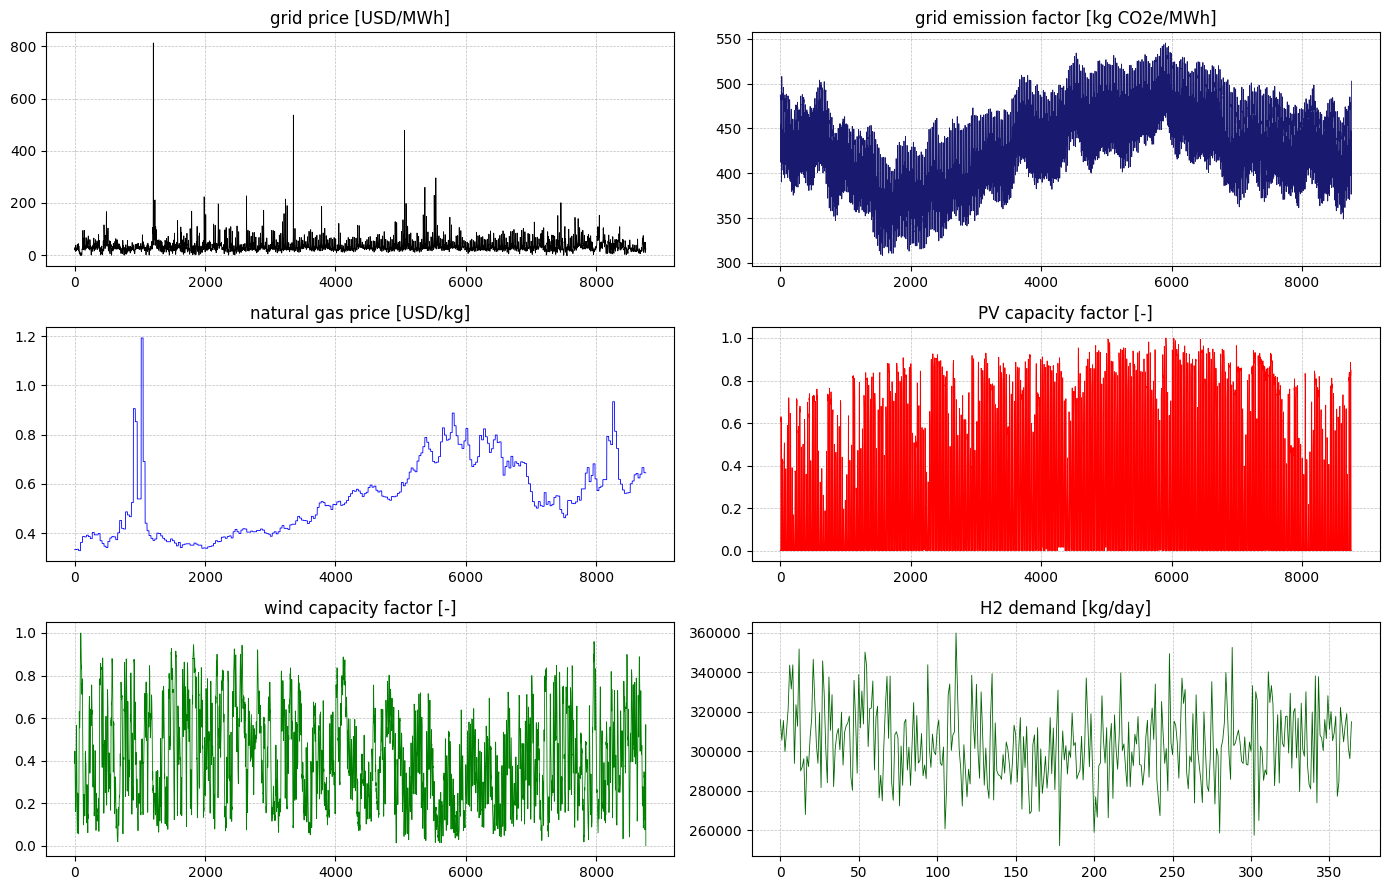

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
series = [('grid price [USD/MWh]', nominal['grid_price'], 'black'), ('grid emission factor [kg CO2e/MWh]', nominal['grid_gwp'], 'midnightblue'),
          ('natural gas price [USD/kg]', nominal['ng_price'], 'blue'), ('PV capacity factor [-]', nominal['capacity_factor']['PV'], 'red'),
          ('wind capacity factor [-]', nominal['capacity_factor']['WF'], 'green'), ('H2 demand [kg/day]', nominal['h2_demand'], 'darkgreen')]
for ax, (label, y, color) in zip(axes.ravel(), series):
    ax.plot(y, color=color, linewidth=0.6)
    ax.set_title(label)
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

## Cost minimization (ramp + minimum load + smoothing, demand met exactly)

In [5]:
cost_model = H2System(nominal, objective='cost', demand_sign='eq', ramp=True, smoothing=True)
print(f'built in {cost_model.build_time:.1f} s: {cost_model.m.NumVars:,} variables, {cost_model.m.NumConstrs:,} constraints')
cost_model.solve(tee=True)
cost_model.summary()

Set parameter Username


Academic license - for non-commercial use only - expires 2027-03-30


Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


built in 22.6 s: 972,454 variables, 552,321 constraints
Set parameter OutputFlag to value 1


Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))


CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]


... (93 outputs left out)

Optimal solution found (tolerance 1.00e-04)


Best objective 2.576439015853e+08, best bound 2.576439015853e+08, gap 0.0000%


termination: optimal  (build 22.6 s, solve 20.9 s)


termination : optimal
objective   : 257,643,901.59  (cost)
total cost  : 257,643,901.59 USD  (capex 182,438, fopex 1,414, vopex 42,144,704, purchase 215,315,346)
total GWP   : 1,447,319,785.08 kg CO2e  (scope 1 1,038,795,029, scope 2 31,945,358, scope 3 376,579,398)
capacities  : D1 100,000,000.0, D2 100,000,000.0, D3 100,000,000.0, D4 100,000,000.0, Grid 100,000,000.0, LiI 25.0, LiI_discharge 25.0, PV 600.0, SMR 23,566.1, WF 650.0
storage     : LiI_Power_stored 142.18


In [6]:
results_cost = cost_model.results()
with open('Gurobipy_res_cost.pkl', 'wb') as f:
    pickle.dump(results_cost, f)
frames_cost = cost_model.frames()
frames_cost['Cap_P']

ATR_CCS_R        0.000000e+00
ATR_CCS_R_OC     0.000000e+00
AWE              0.000000e+00
D1               1.000000e+08
D2               1.000000e+08
D3               1.000000e+08
D4               1.000000e+08
Grid             1.000000e+08
LiI              2.500000e+01
LiI_discharge    2.500000e+01
PEM              0.000000e+00
PV               6.000000e+02
SMR              2.356613e+04
SMRCCS           0.000000e+00
WF               6.500000e+02
dtype: float64

In [7]:
# shadow prices with the binaries fixed: marginal cost of one more kg of hydrogen per day (USD/kg)
sp = cost_model.shadow_prices()
pd.Series(sp['demand']).describe()

count    365.000000
mean       2.327393
std        0.515557
min        1.578319
25%        1.853728
50%        2.282590
75%        2.725387
max        4.124112
dtype: float64

## GWP minimization (ramp + minimum load, no smoothing, as in the original notebook)

In [8]:
gwp_model = H2System(nominal, objective='gwp', demand_sign='eq', ramp=True, smoothing=False)
gwp_model.solve(tee=False)
gwp_model.summary()
results_gwp = gwp_model.results()
with open('Gurobipy_res_gwp.pkl', 'wb') as f:
    pickle.dump(results_gwp, f)
del gwp_model
gc.collect()

Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


termination : optimal
objective   : 2,228,411.58  (gwp)
total cost  : 7,572,225,703.00 USD  (capex 1,243,646, fopex 360,912, vopex 16,984,597, purchase 7,553,636,549)
total GWP   : 2,228,411.58 kg CO2e  (scope 1 0, scope 2 2,228,412, scope 3 0)
capacities  : AWE 360,000.0, D1 100,000,000.0, D2 100,000,000.0, D3 100,000,000.0, D4 100,000,000.0, Grid 100,000,000.0, LiI 25.0, LiI_discharge 25.0, PEM 360,000.0, PV 600.0, SMRCCS 360,000.0, WF 650.0
storage     : LiI_Power_stored 200.00


0

## Epsilon constraint sweep

Cost objective, `demand_sign='geq'`, all operational constraints, total GWP capped at `(1 - pct/100)` times the GWP
of the cost-optimal solution, `pct = 10 ... 100 %`.

In [9]:
GWP_BASE = results_cost['global_warming_potential_network'][0]
print(f'epsilon base (GWP of the cost optimum): {GWP_BASE:,.0f} kg CO2e')

RESULTS_DIR = 'res_red_gurobipy'
os.makedirs(RESULTS_DIR, exist_ok=True)

results = {}
for i in range(10):
    pct = (i + 1) * 10
    print(f'--- model {i + 1}/10: {pct}% reduction ---')
    model = H2System(nominal, objective='cost', demand_sign='geq', ramp=True, smoothing=True)
    model.add_gwp_reduction(GWP_BASE, pct)
    model.solve(tee=False)
    model.summary()
    results[i] = model.results()
    if model.status == 'optimal':
        results[i]['shadow_price_gwp_cap'] = model.shadow_prices()['gwp_cap']     # USD per kg CO2e (fixed binaries)
    with open(f'{RESULTS_DIR}/res_red_{i}.pkl', 'wb') as f:
        pickle.dump(results[i], f)
    del model
    gc.collect()
print('All models solved.')

epsilon base (GWP of the cost optimum): 1,447,319,785 kg CO2e
--- model 1/10: 10% reduction ---


Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


termination : optimal
objective   : 260,727,851.68  (cost)
total cost  : 260,727,851.68 USD  (capex 224,277, fopex 1,531, vopex 48,369,463, purchase 212,132,580)
total GWP   : 1,302,587,806.57 kg CO2e  (scope 1 884,650,589, scope 2 46,789,736, scope 3 371,147,481)
capacities  : ATR_CCS_R 5,081.4, D1 100,000,000.0, D2 100,000,000.0, D3 100,000,000.0, D4 100,000,000.0, Grid 100,000,000.0, LiI 25.0, LiI_discharge 25.0, PV 600.0, SMR 18,741.9, WF 650.0
storage     : LiI_Power_stored 175.00


--- model 2/10: 20% reduction ---


Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


termination : optimal
objective   : 263,950,029.76  (cost)
total cost  : 263,950,029.76 USD  (capex 244,644, fopex 1,628, vopex 54,595,067, purchase 209,108,691)
total GWP   : 1,157,855,828.06 kg CO2e  (scope 1 730,450,187, scope 2 61,692,048, scope 3 365,713,593)
capacities  : ATR_CCS_R 9,796.6, D1 100,000,000.0, D2 100,000,000.0, D3 100,000,000.0, D4 100,000,000.0, Grid 100,000,000.0, LiI 25.0, LiI_discharge 25.0, PV 600.0, SMR 14,066.3, WF 650.0
storage     : LiI_Power_stored 190.72


... (21 outputs left out)

--- model 10/10: 100% reduction ---


Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


termination : infeasibleOrUnbounded


All models solved.


In [10]:
summary_df = tm.export_sweep(results, 'Gurobipy_Tvef_Battery_epsilon_constraint_results.xlsx')
summary_df['shadow_price_USD_per_kgCO2e'] = [results[i].get('shadow_price_gwp_cap') for i in results]
summary_df

Saved results to: Gurobipy_Tvef_Battery_epsilon_constraint_results.xlsx


,termination,total_cost_USD,total_emissions_kg_CO2eq,scope1_kg_CO2eq,scope2_kg_CO2eq,scope3_kg_CO2eq,shadow_price_USD_per_kgCO2e
gwp_reduction_pct,,,,,,,
10,optimal,2.607279e+08,1.302588e+09,8.846506e+08,4.678974e+07,3.711475e+08,-0.021639
20,optimal,2.639500e+08,1.157856e+09,7.304502e+08,6.169205e+07,3.657136e+08,-0.022993
30,optimal,2.673922e+08,1.013124e+09,5.765342e+08,7.629991e+07,3.602897e+08,-0.024585
40,optimal,2.710681e+08,8.683919e+08,4.229138e+08,9.060175e+07,3.548763e+08,-0.026181
50,optimal,2.749087e+08,7.236599e+08,2.696438e+08,1.045409e+08,3.494752e+08,-0.026783
60,optimal,2.788094e+08,5.789279e+08,1.165111e+08,1.183379e+08,3.440789e+08,-0.027087
70,optimal,3.022000e+08,4.341959e+08,4.983368e+07,4.263300e+07,3.417293e+08,-0.307629
80,optimal,6.121482e+08,2.894640e+08,3.683968e+07,0.000000e+00,2.526243e+08,-5.895029
90,optimal,2.028525e+09,1.447320e+08,1.841984e+07,0.000000e+00,1.263121e+08,-12.871395


## Pareto front and ATR_CCS_R profiles

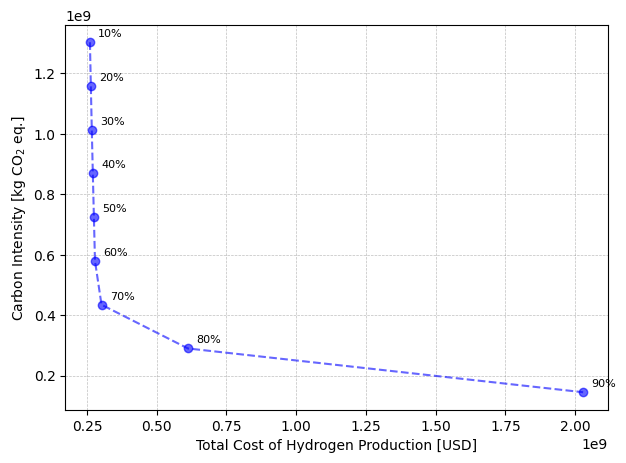

In [11]:
feasible = [i for i in results if results[i]['termination'] == 'optimal']
cost = [results[i]['objective'] for i in feasible]
gwp = [results[i]['global_warming_potential_location'][tm.LOCATION, 0] for i in feasible]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cost, gwp, color='blue', linestyle='--', marker='o', alpha=0.6)
for i, (c, g) in zip(feasible, zip(cost, gwp)):
    ax.annotate(f'{(i + 1) * 10}%', (c, g), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xlabel('Total Cost of Hydrogen Production [USD]')
ax.set_ylabel('Carbon Intensity [kg CO$_2$ eq.]')
ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.show()

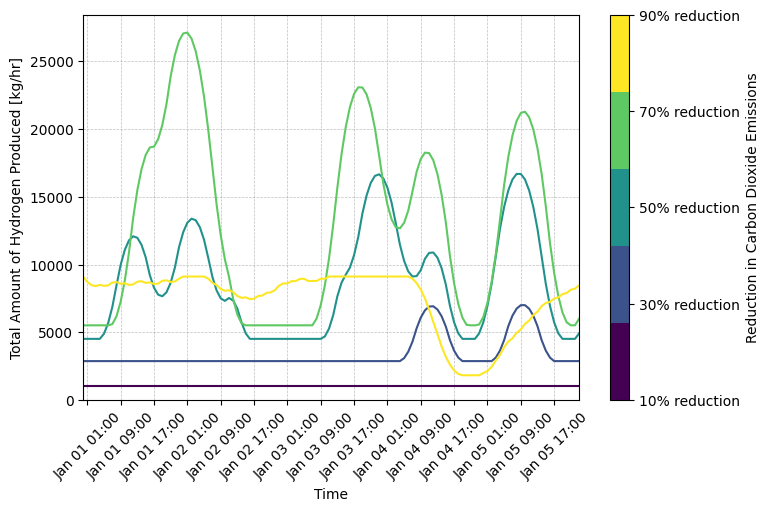

In [12]:
import matplotlib.dates as mdates
from datetime import datetime, timedelta

time_labels = [datetime(2024, 1, 1) + timedelta(days=j, hours=i) for j in range(0, 5) for i in range(24)]
data_sets = [0, 2, 4, 6, 8]
reduction_labels = ['10% reduction', '30% reduction', '50% reduction', '70% reduction', '90% reduction']
cmap = plt.get_cmap('viridis', len(data_sets))

fig, ax = plt.subplots(figsize=(8, 5))
for k, study in enumerate(data_sets):
    if results[study]['termination'] != 'optimal':
        continue
    P = results[study]['P']
    ax.plot(time_labels, [P[tm.LOCATION, 'ATR_CCS_R', 0, d, h] for d in range(0, 5) for h in range(24)],
            color=cmap(k), label=reduction_labels[k])
ax.set_xlabel('Time')
ax.set_ylabel('Total Amount of Hydrogen Produced [kg/hr]')
ax.set_ylim(bottom=0)
ax.set_xlim([time_labels[0], time_labels[-1]])
ax.xaxis.set_major_locator(mdates.HourLocator(interval=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))
plt.setp(ax.get_xticklabels(), rotation=45)
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=len(data_sets) - 1))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(len(data_sets)))
cbar.set_label('Reduction in Carbon Dioxide Emissions')
cbar.set_ticklabels(reduction_labels)
plt.show()

## Scope split along the Pareto front

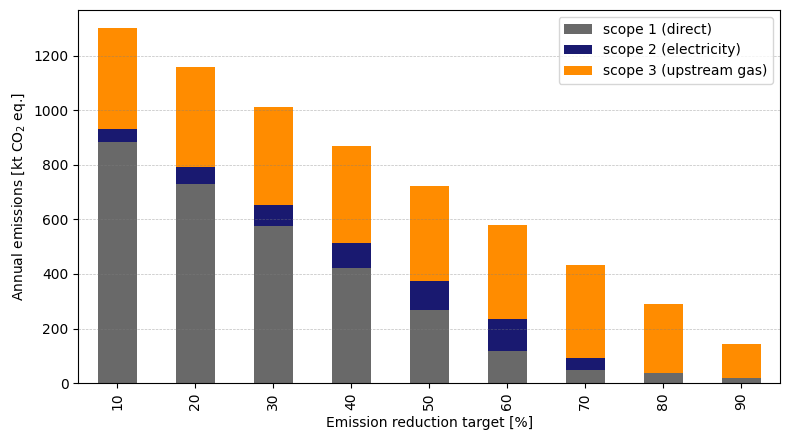

In [13]:
scope_df = summary_df[['scope1_kg_CO2eq', 'scope2_kg_CO2eq', 'scope3_kg_CO2eq']].dropna() / 1e6
scope_df.columns = ['scope 1 (direct)', 'scope 2 (electricity)', 'scope 3 (upstream gas)']
ax = scope_df.plot(kind='bar', stacked=True, figsize=(8, 4.5), color=['dimgray', 'midnightblue', 'darkorange'])
ax.set_xlabel('Emission reduction target [%]')
ax.set_ylabel('Annual emissions [kt CO$_2$ eq.]')
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

## Using the uncertainty handles

Example: the 50 % reduction case under the location-based scope 2 convention with a realized capture rate of 80 %
of design and the 75th percentile grid emission factor, plus a separate cap on scope 3. Compare with the nominal
50 % run above.

In [14]:
inputs_alt = make_inputs(data, {'scope2_convention': 'location', 'capture_rate_factor': 0.8, 'grid_ef_profile': '0.75'})
alt = H2System(inputs_alt, objective='cost', demand_sign='geq', ramp=True, smoothing=True)
alt.add_gwp_reduction(GWP_BASE, 50)
alt.add_gwp_reduction(results_cost['global_warming_potential_scope'][(tm.LOCATION, 3, 0)], 30, scope=3)
alt.solve(tee=False)
alt.summary()
if alt.status == 'optimal':
    print('shadow prices [USD per kg CO2e]:', {k: round(v, 4) for k, v in alt.shadow_prices().items() if k != 'demand'})
    print('nominal 50 % run for comparison (results[4]):')
    print(f"   cost {results[4]['objective']:,.0f} USD, GWP {results[4]['global_warming_potential_network'][0]:,.0f} kg CO2e, "
          f"scopes {[round(results[4]['global_warming_potential_scope'][(tm.LOCATION, s, 0)]) for s in (1, 2, 3)]}")

Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored


termination : optimal
handles     : {'grid_ef_profile': '0.75', 'capture_rate_factor': 0.8, 'scope2_convention': 'location'}
objective   : 570,952,805.43  (cost)
total cost  : 570,952,805.43 USD  (capex 580,065, fopex 152,609, vopex 93,674,421, purchase 476,545,710)
total GWP   : 723,659,892.54 kg CO2e  (scope 1 170,691,939, scope 2 289,362,375, scope 3 263,605,578)
capacities  : ATR_CCS_R 17,052.3, D1 100,000,000.0, D2 100,000,000.0, D3 100,000,000.0, D4 100,000,000.0, Grid 100,000,000.0, LiI 25.0, LiI_discharge 25.0, PEM 216,064.6, PV 600.0, WF 650.0
storage     : LiI_Power_stored 200.00


shadow prices [USD per kg CO2e]: {'gwp_cap': -0.951, 'gwp_cap_scope3': -5.322}
nominal 50 % run for comparison (results[4]):
   cost 274,908,730 USD, GWP 723,659,893 kg CO2e, scopes [269643785, 104540932, 349475176]
